# Notebook 03 — Approach 2: MobileNetV2 Transfer Learning

In [1]:
import os, sys
sys.path.insert(0, '..')
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

from src.dataset import get_train_val_split, load_images_from_folder, OrangeDataset, CLASS_NAMES
from src.dl_model import build_mobilenet, train_one_epoch, evaluate

DATA_DIR = '../data/raw'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 32
EPOCHS = 15
LR = 1e-3

print(f"Using device: {DEVICE}")


Using device: cpu


## 1. Load Data & Build DataLoaders

In [2]:
X_train, X_val, y_train, y_val = get_train_val_split(
    os.path.join(DATA_DIR, 'train'), val_size=0.15
)
X_test, y_test = load_images_from_folder(os.path.join(DATA_DIR, 'test'))

train_ds = OrangeDataset(X_train, y_train, augment=True)
val_ds   = OrangeDataset(X_val,   y_val,   augment=False)
test_ds  = OrangeDataset(X_test,  y_test,  augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")


Train: 842 | Val: 149 | Test: 99


## 2. Build Model

In [3]:
model = build_mobilenet(num_classes=4, freeze_backbone=True).to(DEVICE)

# Count trainable params
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} / {total:,}")


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /Users/rsivaramakrishna/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:02<00:00, 6.23MB/s]


Trainable params: 328,964 / 2,552,836


## 3. Phase 1 — Train Head Only (5 epochs)

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.5)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
patience_counter = 0

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
    vl_loss, vl_acc, _, _ = evaluate(model, val_loader, criterion, DEVICE)
    scheduler.step(vl_loss)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    print(f"Epoch {epoch:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {vl_loss:.4f} Acc: {vl_acc:.4f}")

    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        torch.save(model.state_dict(), '../models/mobilenet_best.pth')
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= 4:
            print("Early stopping triggered.")
            break


Epoch 01 | Train Loss: 0.0995 Acc: 0.9561 | Val Loss: 0.0401 Acc: 0.9866
Epoch 02 | Train Loss: 0.0726 Acc: 0.9798 | Val Loss: 0.0347 Acc: 0.9866
Epoch 03 | Train Loss: 0.0494 Acc: 0.9810 | Val Loss: 0.0385 Acc: 0.9866
Epoch 04 | Train Loss: 0.0802 Acc: 0.9691 | Val Loss: 0.0413 Acc: 0.9866
Epoch 05 | Train Loss: 0.0604 Acc: 0.9762 | Val Loss: 0.0375 Acc: 0.9866
Epoch 06 | Train Loss: 0.0463 Acc: 0.9822 | Val Loss: 0.0451 Acc: 0.9866
Early stopping triggered.


## 4. Training Curves

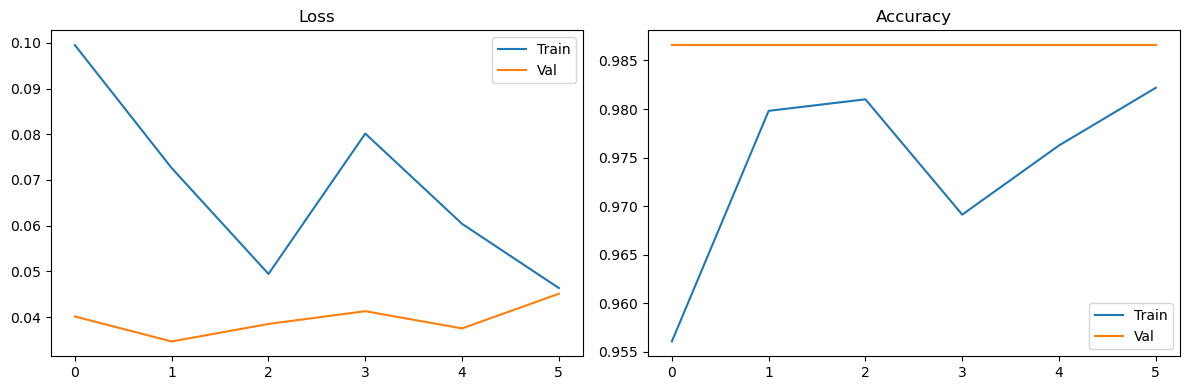

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'],   label='Val')
axes[0].set_title('Loss'); axes[0].legend()

axes[1].plot(history['train_acc'], label='Train')
axes[1].plot(history['val_acc'],   label='Val')
axes[1].set_title('Accuracy'); axes[1].legend()

plt.tight_layout()
plt.savefig('../report/dl_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Test Evaluation

Test Accuracy: 0.9798

              precision    recall  f1-score   support

   blackspot       0.95      0.95      0.95        22
      canker       0.95      0.95      0.95        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.98        99
   macro avg       0.98      0.98      0.98        99
weighted avg       0.98      0.98      0.98        99



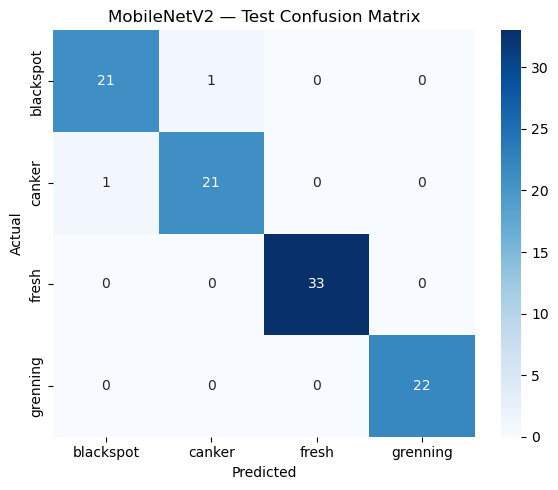

In [7]:
model.load_state_dict(torch.load('../models/mobilenet_best.pth', map_location=DEVICE))
_, test_acc, test_preds, test_labels = evaluate(model, test_loader, criterion, DEVICE)

print(f"Test Accuracy: {test_acc:.4f}\n")
print(classification_report(test_labels, test_preds, target_names=CLASS_NAMES))

cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('MobileNetV2 — Test Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('../report/dl_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
